In [1]:
from scipy.io import loadmat
import mat73

from tqdm.notebook import tqdm

import numpy as np
import pandas as pd

from matplotlib import pyplot as plt
from matplotlib import colorbar as mbar
import seaborn as sns

from scipy.ndimage import gaussian_filter as smooth

from scipy.stats import zscore
from scipy.stats import sem
from scipy.stats import spearmanr as spearman

from scipy.stats import permutation_test

import warnings
warnings.filterwarnings('ignore')
from IPython.display import clear_output

# Definitions

In [2]:
def m_plot(input_data, colors, error_method='sem', smooth_win=0, labels=[], plot_title='', XAxisTicks=[], figure_size=(8,3)):
    '''
    Args:
        input_data:   (N,M,T) matrix of input data, (Conditions,Samples,Timepoints)
        colors:       (N,4) matrix of colors for the generated plots in [R,G,B,FaceAlpha] format,
                      where N is the number of conditions. FaceAlpha in the scale=[0-255]
        error_method: variation metric ('sem' & 'std')
        smooth_win:   smoothing window
        
        labels:       (N,) list of labels for the generated plots, where N is the number of conditions
        plot_title:   title of the generated plot
        XAxisTicks:   (N,) vaetor of XAxisTicks
        figure_size:  two-item tuple containing width and height of the figure
    Returns:
        none
    '''

    colors = np.array(colors) / np.array(255)
    if not labels: labels=['']*len(input_data)
    XAxisTicks = np.array(XAxisTicks)
    if XAxisTicks.size==0: XAxisTicks = np.arange(0,input_data[0].shape[1])
    
    plt.figure(figsize=figure_size)
    for i,Cond in enumerate(input_data):
        data_ave = smooth(np.nanmean(Cond, axis=0), smooth_win)
        data_std = smooth(np.nanstd(Cond, axis=0), smooth_win)
        
        if error_method=='sem':
            error_up  = data_ave + (data_std / np.sqrt(Cond.shape[0]))
            error_low = data_ave - (data_std / np.sqrt(Cond.shape[0]))
        elif error_method=='std':
            error_up  = data_ave + data_std
            error_low = data_ave - data_std

        plt.fill_between(XAxisTicks, error_up, error_low, color=colors[i], label='_nolegend_')
        plt.plot(XAxisTicks, data_ave, color=colors[i,:3], lw=figure_size[0]*.5, label=labels[i])
    
    ylim = plt.ylim()
    plt.legend(frameon=False, fontsize=figure_size[0]*1.5)
    plt.title(plot_title, fontsize=figure_size[0]*1.8)
    # plt.rcParams.update({'font.size': figure_size[0]*.5})
    plt.tight_layout()


def comp_permute_p(vec1, vec2, permute_reps=100001):
    '''
    Args:
        vec1:         (N,) vector of data 1st distribution (Samples,)
        vec2:         (N,) vector of data 2nd distribution (Samples,)
        permute_reps: number of repetitions for the permutation process
    Returns:
        p_val: two-tailed p-value of the permutation process for [vec2 - vec1]
    '''

    vec1 = vec1[np.where((~np.isnan(vec1)))[0]]
    vec2 = vec2[np.where((~np.isnan(vec2)))[0]]

    def tmp_test_stat(x, y, axis):
        return np.nanmean(x, axis=axis) - np.nanmean(y, axis=axis)
    
    p_val = np.nan
    p_val = permutation_test(data=(vec2, vec1), statistic=tmp_test_stat, vectorized=True, axis=0, random_state=15, n_resamples=permute_reps).pvalue

    return p_val


def OutlierRemover(input_data):
    '''
    Args:
        input_data: (N,) vector of input data
    Returns:
        (M,) vector of data with outliers removed
    '''
    
    return np.array(input_data[abs(zscore(input_data))<3])

def compute_dprime(data1, data2):
    '''
    Args:
        data1: data for condition 1, shape (N,)
        data2: data for condition 2, shape (N,)
    Returns:
        d-prime value between the two data distributions, for data1-data2
    '''
    
    return (np.nanmean(data1) - np.nanmean(data2)) / np.sqrt(.5 * (np.nanvar(data1) + np.nanvar(data2)) )


def nansem(vec):
    '''
    Args:
        vec: vector of data
    Returns:
        nansem for vec
    '''
    vec = np.array(vec)
    vec = vec[np.where((~np.isnan(vec)))[0]]

    return np.std(vec) / np.sqrt(vec.shape[0]-1)


# Load Data


In [27]:
FigDir = '../Results/figs_pac/'

fl_num = 0
fl_names = ['PFC2PFC', 'OB2OB', 'PFC2OB', 'OB2PFC']
sel_file_nm = fl_names[fl_num]
tmp_FileDir = f'../Results/results/YMT_PAC_v02_division_{sel_file_nm}.mat'
tmp_File = mat73.loadmat(tmp_FileDir)

sig_thresh_1, sig_thresh_2 = .05, .001

# color
color_b, color_w, color_c = [100, 100, 100, 80], [222, 49, 99, 80], [50, 142, 110, 80]
color_b_n, color_w_n, color_c_n = np.array(color_b[:3])/255, np.array(color_w[:3])/255, np.array(color_c[:3])/255

freqs_phase = tmp_File['phase_freq']
freqs_amp   = tmp_File['amp_freq']

idx_band_delta_ph = np.where((freqs_phase<=4))[0]
idx_band_theta_ph = np.where((freqs_phase>4) & (freqs_phase<=12))[0]

pac_b = tmp_File['baseline_corrected_PAC_baseline']
pac_w = tmp_File['baseline_corrected_PAC_wrong']
pac_c = tmp_File['baseline_corrected_PAC_correct']

ave_pac_b = np.nanmean(pac_b, axis=0)
ave_pac_w = np.nanmean(pac_w, axis=0)
ave_pac_c = np.nanmean(pac_c, axis=0)

ave_pac_freq_b = np.nanmean(pac_b, axis=1)
ave_pac_freq_w = np.nanmean(pac_w, axis=1)
ave_pac_freq_c = np.nanmean(pac_c, axis=1)

In [28]:
num_conds, num_max_tr = 3, np.max([pac_b.shape[0], pac_w.shape[0], pac_c.shape[0]])

pac_delta = np.zeros((num_conds, num_max_tr)) * np.nan
pac_theta = np.copy(pac_delta)

pac_delta[0,:pac_b.shape[0]] = np.nanmean(np.nanmean(pac_b[:,:,idx_band_delta_ph], axis=1), axis=1)
pac_delta[1,:pac_w.shape[0]] = np.nanmean(np.nanmean(pac_w[:,:,idx_band_delta_ph], axis=1), axis=1)
pac_delta[2,:pac_c.shape[0]] = np.nanmean(np.nanmean(pac_c[:,:,idx_band_delta_ph], axis=1), axis=1)

pac_theta[0,:pac_b.shape[0]] = np.nanmean(np.nanmean(pac_b[:,:,idx_band_theta_ph], axis=1), axis=1)
pac_theta[1,:pac_w.shape[0]] = np.nanmean(np.nanmean(pac_w[:,:,idx_band_theta_ph], axis=1), axis=1)
pac_theta[2,:pac_c.shape[0]] = np.nanmean(np.nanmean(pac_c[:,:,idx_band_theta_ph], axis=1), axis=1)

In [29]:
pval_wb = np.zeros_like(freqs_phase) * np.nan
pval_cb = np.copy(pval_wb)

for iFreq in tqdm(range(freqs_phase.shape[0])):
    pval_wb[iFreq] = comp_permute_p(ave_pac_freq_w[:,iFreq], ave_pac_freq_b[:,iFreq], permute_reps=10001)
    pval_cb[iFreq] = comp_permute_p(ave_pac_freq_c[:,iFreq], ave_pac_freq_b[:,iFreq], permute_reps=10001)


  0%|          | 0/23 [00:00<?, ?it/s]

In [30]:
sigline_loc_wb, sigline_loc_cb = 5.8, 5.6

sigtime_wb_thr1 = (pval_wb<sig_thresh_1).astype('float') * sigline_loc_wb
sigtime_wb_thr1[sigtime_wb_thr1==0] = np.nan

sigtime_wb_thr2 = (pval_wb<sig_thresh_2).astype('float') * sigline_loc_wb
sigtime_wb_thr2[sigtime_wb_thr2==0] = np.nan

sigtime_cb_thr1 = (pval_cb<sig_thresh_1).astype('float') * sigline_loc_cb
sigtime_cb_thr1[sigtime_cb_thr1==0] = np.nan

sigtime_cb_thr2 = (pval_cb<sig_thresh_2).astype('float') * sigline_loc_cb
sigtime_cb_thr2[sigtime_cb_thr2==0] = np.nan

# Plot: average

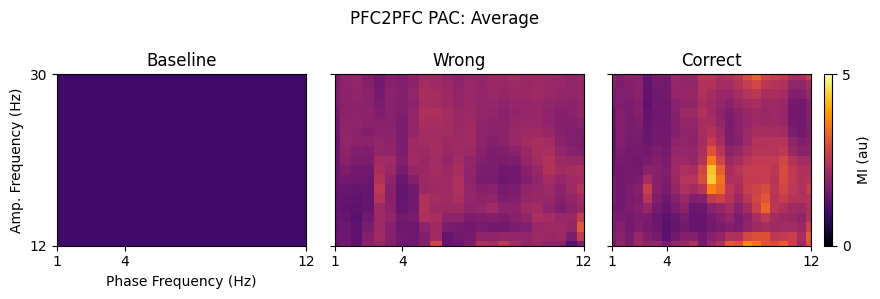

In [31]:
fig_sz = np.array((9,3)) * 1
plot_xlim = [min(freqs_phase), max(freqs_phase)]
plot_ylim = [min(freqs_amp), max(freqs_amp)]
plot_clim = [0, 5]
colormap = 'inferno'
save_fig = 0

fig, axs = plt.subplots(figsize=fig_sz, ncols=3, nrows=1, sharex=True, sharey=True)

axs[0].pcolor(freqs_phase, freqs_amp, ave_pac_b, cmap=colormap, rasterized=True, clim=plot_clim)
axs[0].set_xlim(plot_xlim)
axs[0].set_xticks([plot_xlim[0], 4, plot_xlim[1]])
axs[0].set_xlabel('Phase Frequency (Hz)')
axs[0].set_ylim(plot_ylim)
axs[0].set_yticks(plot_ylim)
axs[0].set_ylabel('Amp. Frequency (Hz)')
axs[0].set_title('Baseline')

axs[1].pcolor(freqs_phase, freqs_amp, ave_pac_w, cmap=colormap, rasterized=True, clim=plot_clim)
axs[1].set_title('Wrong')

ax2 = axs[2].pcolor(freqs_phase, freqs_amp, ave_pac_c, cmap=colormap, rasterized=True, clim=plot_clim)
axs[2].set_title('Correct')

fig.colorbar(mappable=ax2, ticks=plot_clim, label='MI (au)')
plt.suptitle(f'{sel_file_nm} PAC: Average')
plt.tight_layout()

if save_fig: plt.savefig(f'{FigDir}pac_{sel_file_nm.lower()}_average.svg')

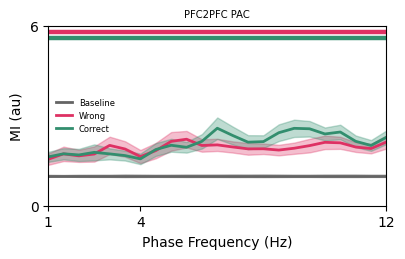

In [32]:
smooth_win = 0
plot_xlim = [1,12]
plot_xticks = [1,4,12]
plot_ylim = [0,6]
figure_size = np.array((4,2.5)) * 1
plot_sigline_lw_thr1, plot_sigline_lw_thr2 = figure_size[0]*.4, figure_size[0]*.8
save_fig = 0

m_plot([ave_pac_freq_b, ave_pac_freq_w, ave_pac_freq_c]
       , [color_b,color_w,color_c], error_method='sem', smooth_win=smooth_win
       , labels=['Baseline','Wrong','Correct'], plot_title=f'{sel_file_nm} PAC'
       , XAxisTicks=freqs_phase, figure_size=figure_size)

plt.plot(freqs_phase, sigtime_wb_thr1, color=color_w_n, lw=plot_sigline_lw_thr1)
plt.plot(freqs_phase, sigtime_wb_thr2, color=color_w_n, lw=plot_sigline_lw_thr2)

plt.plot(freqs_phase, sigtime_cb_thr1, color=color_c_n, lw=plot_sigline_lw_thr1)
plt.plot(freqs_phase, sigtime_cb_thr2, color=color_c_n, lw=plot_sigline_lw_thr2)

plt.xlabel('Phase Frequency (Hz)')
plt.xlim(plot_xlim)
plt.xticks(plot_xticks)

plt.ylabel('MI (au)')
plt.ylim(plot_ylim)
plt.yticks(plot_ylim)

clear_output()
if save_fig: plt.savefig(f'{FigDir}pac_{sel_file_nm.lower()}_spectrum.svg')

# Stat

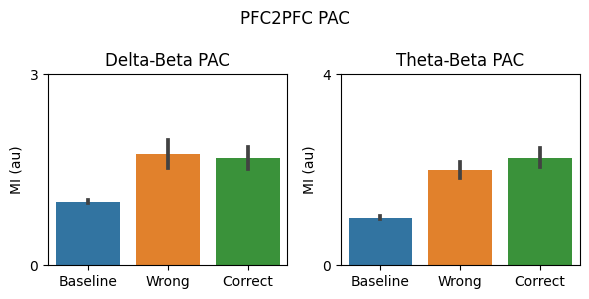

In [33]:
plot_xticks = ['Baseline', 'Wrong', 'Correct']
error_method = 'se'
estimator = 'mean'
figure_size = np.array((6,3)) * 1
save_fig = 0

fig1, ax = plt.subplots(nrows=1, ncols=2, figsize=figure_size, sharex=True)

plt_delta = sns.barplot(ax=ax[0], data=pac_delta.T, estimator=estimator, errorbar=error_method)
ax[0].set_ylim([0,3])
ax[0].set_yticks([0,3])
ax[0].set_ylabel('MI (au)')
ax[0].set_title(f'Delta-Beta PAC')
plt_delta.set(xticklabels=plot_xticks)

plt_delta = sns.barplot(ax=ax[1], data=pac_theta.T, estimator=estimator, errorbar=error_method)
ax[1].set_ylim([0,4])
ax[1].set_yticks([0,4])
ax[1].set_ylabel('MI (au)')
ax[1].set_title(f'Theta-Beta PAC')
plt_delta.set(xticklabels=plot_xticks)

plt.suptitle(f'{sel_file_nm} PAC')
plt.tight_layout()

if save_fig: plt.savefig(f'{FigDir}pac_{sel_file_nm.lower()}_stat.svg')

In [34]:
print(f'Stat for {sel_file_nm} PAC: ')
print(f'............................')

print(f'Delta Baseline = {np.nanmean(pac_delta[0]).round(2)} -+ {nansem(pac_delta[0]).round(2)}')
print(f'Delta Wrong    = {np.nanmean(pac_delta[1]).round(2)} -+ {nansem(pac_delta[1]).round(2)}')
print(f'Delta Correct  = {np.nanmean(pac_delta[2]).round(2)} -+ {nansem(pac_delta[2]).round(2)}')
print(f"----------")
print(f"Delta WB p-val: C vs. W = {comp_permute_p(pac_delta[1], pac_delta[0]).round(5)}")
print(f"Delta CB p-val: C vs. W = {comp_permute_p(pac_delta[2], pac_delta[0]).round(5)}")
print(f"Delta CW p-val: C vs. W = {comp_permute_p(pac_delta[2], pac_delta[1]).round(2)}")
print(f"=====================")
print(f"+=+=+=+=+=+=+=+=+=+=+")
print(f"=====================")
print(f'Theta Baseline = {np.nanmean(pac_theta[0]).round(2)} -+ {nansem(pac_theta[0]).round(2)}')
print(f'Theta Wrong    = {np.nanmean(pac_theta[1]).round(2)} -+ {nansem(pac_theta[1]).round(2)}')
print(f'Theta Correct  = {np.nanmean(pac_theta[2]).round(2)} -+ {nansem(pac_theta[2]).round(2)}')
print(f"----------")
print(f"Theta WB p-val: C vs. W = {comp_permute_p(pac_theta[1], pac_theta[0]).round(5)}")
print(f"Theta CB p-val: C vs. W = {comp_permute_p(pac_theta[2], pac_theta[0]).round(5)}")
print(f"Theta CW p-val: C vs. W = {comp_permute_p(pac_theta[2], pac_theta[1]).round(2)}")


Stat for PFC2PFC PAC: 
............................
Delta Baseline = 1.0 -+ 0.03
Delta Wrong    = 1.74 -+ 0.22
Delta Correct  = 1.68 -+ 0.17
----------
Delta WB p-val: C vs. W = 4e-05
Delta CB p-val: C vs. W = 2e-05
Delta CW p-val: C vs. W = 0.84
+=+=+=+=+=+=+=+=+=+=+
Theta Baseline = 1.0 -+ 0.03
Theta Wrong    = 2.0 -+ 0.17
Theta Correct  = 2.25 -+ 0.2
----------
Theta WB p-val: C vs. W = 2e-05
Theta CB p-val: C vs. W = 2e-05
Theta CW p-val: C vs. W = 0.35
